In [1]:
import pandas as pd

In [2]:
df = pd.read_csv ('202410DatasetEVOfficeParking_v0.csv')

In [3]:
df.head()

,EV_id_x,start_datetime,end_datetime,total_energy,rail,evse_uid,channel,capacity_kwh,commute_km_range_min,commute_km_range_max,EV_brand_selfreported,EV_model_selfreported,capacity_kwh_selfreported,ownership
0,EV0,25-08-2020 11:56,25-08-2020 12:08,1.477,mennekes,600001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EV0,25-08-2020 12:20,25-08-2020 12:32,1.333,mennekes,600002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EV0,25-08-2020 12:40,25-08-2020 13:01,2.330,mennekes,600003,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EV0,25-08-2020 13:05,25-08-2020 13:37,3.764,mennekes,600005,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EV0,25-08-2020 14:03,25-08-2020 14:23,2.297,mennekes,600000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55379 entries, 0 to 55378
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   EV_id_x                    55379 non-null  object 
 1   start_datetime             55379 non-null  object 
 2   end_datetime               55379 non-null  object 
 3   total_energy               55379 non-null  float64
 4   rail                       55379 non-null  object 
 5   evse_uid                   55379 non-null  int64  
 6   channel                    55379 non-null  int64  
 7   capacity_kwh               3829 non-null   float64
 8   commute_km_range_min       4053 non-null   float64
 9   commute_km_range_max       4053 non-null   float64
 10  EV_brand_selfreported      4053 non-null   object 
 11  EV_model_selfreported      4053 non-null   object 
 12  capacity_kwh_selfreported  4053 non-null   object 
 13  ownership                  3773 non-null   obj

In [5]:
df.describe()

,total_energy,evse_uid,channel,capacity_kwh,commute_km_range_min,commute_km_range_max
count,55379.000000,5.537900e+04,55379.000000,3829.000000,4053.000000,4053.000000
mean,21.546110,1.323634e+08,1.485888,49.856516,39.747841,65.107328
std,14.885161,3.367442e+08,0.499805,30.120164,23.105836,37.930413
min,1.000000,6.000000e+05,1.000000,6.000000,0.000000,20.000000
25%,9.280000,1.802535e+06,1.000000,12.000000,21.000000,40.000000
50%,17.560000,1.802641e+06,1.000000,58.000000,41.000000,60.000000
75%,31.040000,1.802672e+06,2.000000,75.000000,61.000000,80.000000
max,88.500000,1.000123e+09,2.000000,125.000000,81.000000,170.000000


In [6]:
df['start_datetime'] = pd.to_datetime(df['start_datetime'], dayfirst = True)
df['end_datetime'] = pd.to_datetime(df['end_datetime'], dayfirst = True )

df['duration_min'] = (df['end_datetime'] - df['start_datetime']).dt.total_seconds() / 60
df['avg_power_kw'] = df['total_energy'] / (df['duration_min'] / 60)

In [7]:
df.head()

,EV_id_x,start_datetime,end_datetime,total_energy,rail,evse_uid,channel,capacity_kwh,commute_km_range_min,commute_km_range_max,EV_brand_selfreported,EV_model_selfreported,capacity_kwh_selfreported,ownership,duration_min,avg_power_kw
0,EV0,2020-08-25 11:56:00,2020-08-25 12:08:00,1.477,mennekes,600001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.385000
1,EV0,2020-08-25 12:20:00,2020-08-25 12:32:00,1.333,mennekes,600002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,6.665000
2,EV0,2020-08-25 12:40:00,2020-08-25 13:01:00,2.330,mennekes,600003,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.0,6.657143
3,EV0,2020-08-25 13:05:00,2020-08-25 13:37:00,3.764,mennekes,600005,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.0,7.057500
4,EV0,2020-08-25 14:03:00,2020-08-25 14:23:00,2.297,mennekes,600000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.0,6.891000


In [8]:
import numpy as np

df['label'] = 0

attack_df = df.sample(n=3000, random_state=42).copy()

n = len(attack_df)
attack_types = np.random.choice(['fdi', 'ddos', 'mitm'], size=n)

for i, atype in zip(attack_df.index, attack_types):
    if atype == 'fdi':
        attack_df.loc[i, 'total_energy'] *= np.random.uniform(1.5, 3)       # pehle 5-10x tha
    elif atype == 'ddos':
        attack_df.loc[i, 'duration_min'] *= np.random.uniform(0.3, 0.5)     # pehle 0.1-1 min fixed tha
        attack_df.loc[i, 'avg_power_kw'] = attack_df.loc[i, 'total_energy'] / (attack_df.loc[i, 'duration_min'] / 60)
    elif atype == 'mitm':
        attack_df.loc[i, 'avg_power_kw'] *= np.random.uniform(-0.5, 0.5)    # pehle -3 se -1 tha (poora negative)

attack_df['label'] = 1

final_df = pd.concat([df, attack_df], ignore_index=True)
final_df['label'].value_counts()

label
0    55379
1     3000
Name: count, dtype: int64

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

features = ['total_energy', 'duration_min', 'avg_power_kw']
X = final_df[features]
y = final_df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9838129496402878
Precision: 0.9438444924406048
Recall: 0.7283333333333334
F1 Score: 0.8222013170272813
Confusion Matrix:
 [[11050    26]
 [  163   437]]


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

# Logistic Regression ko scaled data chahiye hota (Random Forest ko zaroorat nahi thi)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
}

results = []

for name, m in models.items():
    if name == 'Logistic Regression':
        m.fit(X_train_scaled, y_train)
        pred = m.predict(X_test_scaled)
    else:
        m.fit(X_train, y_train)
        pred = m.predict(X_test)
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred)
    })

comparison_df = pd.DataFrame(results)
comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.611083,0.086464,0.686667,0.153588
1,Decision Tree,0.973535,0.744538,0.738333,0.741423
2,Random Forest,0.983813,0.943844,0.728333,0.822201


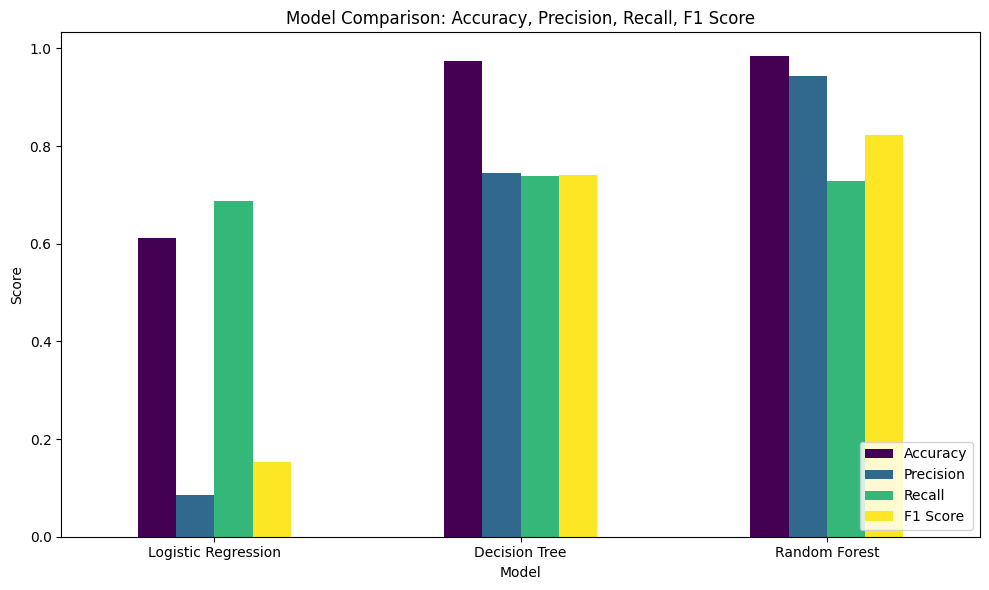

In [11]:
import matplotlib.pyplot as plt

# Graph 1: Model comparison bar chart
comparison_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(
    kind='bar', figsize=(10, 6), colormap='viridis'
)
plt.title('Model Comparison: Accuracy, Precision, Recall, F1 Score')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300)
plt.show()

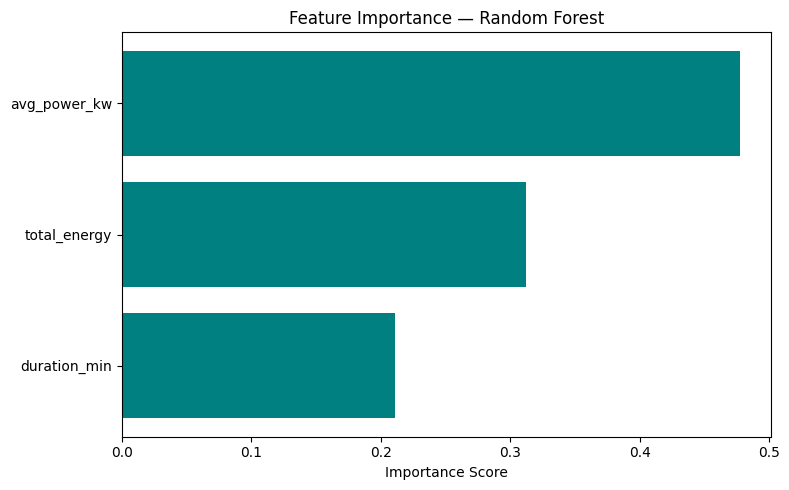

,Feature,Importance
2,avg_power_kw,0.477484
0,total_energy,0.311855
1,duration_min,0.210661


In [12]:
# Graph 2: Feature importance 
importances = model.feature_importances_
feat_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(feat_importance_df['Feature'], feat_importance_df['Importance'], color='teal')
plt.xlabel('Importance Score')
plt.title('Feature Importance — Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

feat_importance_df

In [13]:
from sklearn.ensemble import IsolationForest

iso_model = IsolationForest(contamination=0.05, random_state=42)
iso_model.fit(X_train)

iso_pred = iso_model.predict(X_test)
iso_pred = [1 if p == -1 else 0 for p in iso_pred]

print("Accuracy:", accuracy_score(y_test, iso_pred))
print("Precision:", precision_score(y_test, iso_pred))
print("Recall:", recall_score(y_test, iso_pred))
print("F1 Score:", f1_score(y_test, iso_pred))

Accuracy: 0.9286570743405276
Precision: 0.30287648054145516
Recall: 0.29833333333333334
F1 Score: 0.30058774139378674


In [14]:
import joblib
joblib.dump(model, 'rf_model.pkl')

['rf_model.pkl']